# Forecasting and Machine Learning

In this part we answer five forecasting questions using the cleaned Olist data.
 # | Forecasting question |
|---|---------------------------------------------------------|
|1.| How many orders will we get per week in the coming weeks?|
|2.| What will the weekly revenue be?|
|3.| Which orders are likely to be delivered late?|
|4.| How many days will a new order take to be delivered?|
|5.| How many orders will the three biggest states (São Paulo, Rio de Janeiro and Minas Gerais) have?|

Questions 1, 2 and 5 are time series problems. Question 3 is a classification problem and question 4 is a regression problem.

The data is the cleaned Excel file from the cleaning step (8,002 orders, from January 2017 to August 2018). It is a random sample of the full Olist data, so the numbers are smaller than the real ones, but the trends should look similar.

For questions 3 and 4 we predict at the moment the customer places the order, so we only use information that we would know at that time. For example, we don't use review scores or delivery dates.

## 1. Loading the data

First we import the libraries and put the settings at the top (the file name and the order statuses we want to exclude). Then we load only the two tables we need for the time series: Orders (for the dates and status) and Order_Items (for the prices).

We exclude canceled and unavailable orders because they never turned into real sales. They are only about 1.3% of the orders, but counting them would make the weekly numbers a little too high.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE = "olist_Cleaned_Dataset.xlsx"

# orders that never became real demand
EXCLUDE_STATUS = ["canceled", "unavailable"]

print("pandas", pd.__version__)

pandas 3.0.5


In [3]:
orders = pd.read_excel(FILE, sheet_name="Orders")
items  = pd.read_excel(FILE, sheet_name="Order_Items")

orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])

print("Orders:", orders.shape)
print("Order_Items:", items.shape)
print("\nPurchase date range:",
      orders["order_purchase_timestamp"].min(), "->", orders["order_purchase_timestamp"].max())
print("\nOrder status counts:")
print(orders["order_status"].value_counts())

Orders: (8002, 8)
Order_Items: (8942, 9)

Purchase date range: 2017-01-05 12:11:23 -> 2018-08-29 09:14:11

Order status counts:
order_status
delivered      7746
shipped         104
unavailable      56
canceled         47
processing       29
invoiced         20
Name: count, dtype: int64


## 2. Valid orders and revenue per order

Now we remove the canceled and unavailable orders, because they never became real sales.

Then we calculate the revenue of each order as the sum of its item prices. We don't include the freight value, so the revenue only reflects the products.

In [4]:
valid = orders[~orders["order_status"].isin(EXCLUDE_STATUS)].copy()

print("All orders:", len(orders))
print("Valid orders:", len(valid))
print("Removed:", len(orders) - len(valid))

All orders: 8002
Valid orders: 7899
Removed: 103


In [5]:
revenue = items.groupby("order_id")["price"].sum().rename("revenue")

valid = valid.merge(revenue, on="order_id", how="left")
print("Valid orders without items:", valid["revenue"].isna().sum())

valid["revenue"] = valid["revenue"].fillna(0)

print("Total revenue:", round(valid["revenue"].sum(), 2))
print(valid["revenue"].describe().round(2))

Valid orders without items: 0
Total revenue: 1064064.27
count     7899.00
mean       134.71
std        242.63
min          3.90
25%         45.00
50%         84.90
75%        149.90
max      13440.00
Name: revenue, dtype: float64


We removed 103 orders (47 canceled and 56 unavailable), so 7,899 valid orders are left. Every valid order has at least one item. The total revenue is about 1.06 million BRL. The average order is around 135 BRL, but the median is only about 85, so a few expensive orders pull the average up (the biggest one is 13,440).

## 3. Weekly series

Now we group the valid orders by week. Each week runs from Monday to Sunday, and we label it with the Sunday date.

The data starts on Thursday 5 January 2017 and ends on Wednesday 29 August 2018, so the first and the last weeks are not complete. If we keep them they will look like a fake drop in orders, so we remove them.

We also mark the week of Black Friday (24 November 2017), because it is much higher than the other weeks and we will need to treat it carefully later.

In [6]:
weekly = (valid.set_index("order_purchase_timestamp")
                .resample("W-SUN")
                .agg(orders=("order_id", "count"), revenue=("revenue", "sum")))

print("Number of weeks:", len(weekly))
print(weekly.head(3).round(2))
print(weekly.tail(3).round(2))

Number of weeks: 87
                          orders  revenue
order_purchase_timestamp                 
2017-01-08                     7   335.39
2017-01-15                     5   399.59
2017-01-22                    17  1980.10
                          orders   revenue
order_purchase_timestamp                  
2018-08-19                   142  16229.82
2018-08-26                    88  12130.47
2018-09-02                     6    421.80


In [7]:
first_day = valid["order_purchase_timestamp"].min().normalize()
last_day = valid["order_purchase_timestamp"].max().normalize()

week_start = weekly.index - pd.Timedelta(days=6)
complete = (week_start >= first_day) & (weekly.index <= last_day)

print("Removed weeks:", list(weekly.index[~complete].date))
weekly = weekly[complete].copy()

black_friday = pd.Timestamp("2017-11-24")
weekly["black_friday_week"] = ((black_friday >= weekly.index - pd.Timedelta(days=6))
                               & (black_friday <= weekly.index))

print("Weeks kept:", len(weekly))
print("From", weekly.index.min().date(), "to", weekly.index.max().date())
print(weekly[weekly["black_friday_week"]].round(2))
print(weekly[["orders", "revenue"]].describe().round(1))

Removed weeks: [datetime.date(2017, 1, 8), datetime.date(2018, 9, 2)]
Weeks kept: 85
From 2017-01-15 to 2018-08-26
                          orders   revenue  black_friday_week
order_purchase_timestamp                                     
2017-11-26                   251  32907.79               True
       orders  revenue
count    85.0     85.0
mean     92.8  12509.5
std      43.6   5990.4
min       5.0    399.6
25%      62.0   7930.3
50%      82.0  11589.8
75%     129.0  17563.0
max     251.0  32907.8


We have 85 complete weeks, from 15 January 2017 to 26 August 2018. The week of Black Friday (ending 26 November 2017) has 251 orders, which is almost three times the average week (about 93).

## 4. Plotting the weekly series

Before building any model we look at the two series. The red dot marks the week of Black Friday.

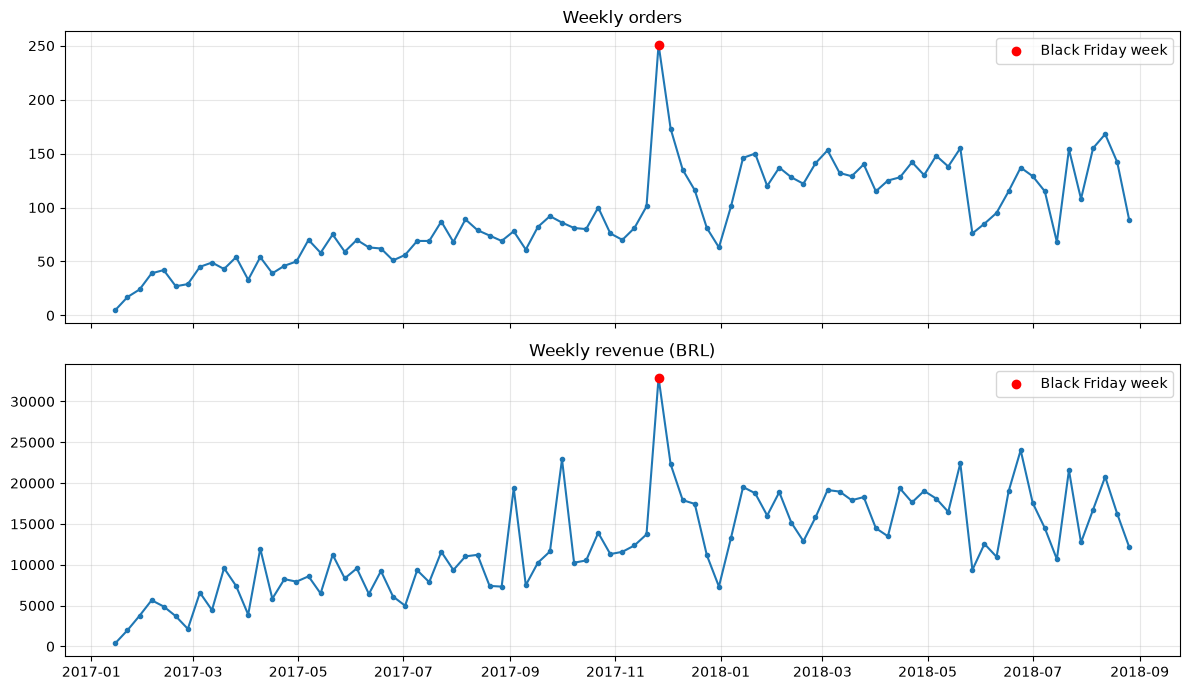

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

titles = {"orders": "Weekly orders", "revenue": "Weekly revenue (BRL)"}

for ax, col in zip(axes, ["orders", "revenue"]):
    ax.plot(weekly.index, weekly[col], marker="o", markersize=3)
    bf = weekly[weekly["black_friday_week"]]
    ax.scatter(bf.index, bf[col], color="red", zorder=3, label="Black Friday week")
    ax.set_title(titles[col])
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("weekly_series.png", dpi=150)
plt.show()

In [9]:
weekly.to_csv("weekly_series.csv")
print("Saved", len(weekly), "weeks")

Saved 85 weeks


Both series grow during 2017 and then become more stable in 2018 (around 115 to 155 orders per week). The first weeks of 2017 are very low, which looks like the start of the platform, so it may affect the models. Black Friday is a clear peak. The revenue has two jumps in September and October 2017 that do not appear in the orders, so they come from a few expensive orders. We also see a drop at the end of May 2018 and in July 2018.

## 5. Train/test split and baselines

To check a forecast we need to hide some weeks from the model. We keep the last 12 weeks as the test set (June to August 2018) and use the weeks before them for training.

Before building any model we try very simple forecasts, for example repeating the last week or using the average of the last few weeks. Any real model has to be better than these, otherwise it is not worth using.

We measure the error with two numbers:
- MAPE: the average error as a percentage of the real value.
- RMSE: the typical size of the error, in the same unit as the data (orders or BRL).

In [10]:
HOLDOUT_WEEKS = 12

train = weekly.iloc[:-HOLDOUT_WEEKS]
test = weekly.iloc[-HOLDOUT_WEEKS:]

print("Train:", train.index.min().date(), "->", train.index.max().date(), "|", len(train), "weeks")
print("Test: ", test.index.min().date(), "->", test.index.max().date(), "|", len(test), "weeks")

Train: 2017-01-15 -> 2018-06-03 | 73 weeks
Test:  2018-06-10 -> 2018-08-26 | 12 weeks


In [11]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def baselines(col):
    values = {
        "Last week": train[col].iloc[-1],
        "Mean of last 4 weeks": train[col].iloc[-4:].mean(),
        "Mean of last 8 weeks": train[col].iloc[-8:].mean(),
        "Mean of all training weeks": train[col].mean(),
    }
    rows = []
    for name, value in values.items():
        pred = np.full(len(test), value)
        rows.append({
            "baseline": name,
            "forecast": round(value, 1),
            "MAPE %": round(mape(test[col].values, pred), 1),
            "RMSE": round(rmse(test[col].values, pred), 1),
        })
    return pd.DataFrame(rows)

In [12]:
print("ORDERS")
print(baselines("orders").to_string(index=False))

print("\nREVENUE")
print(baselines("revenue").to_string(index=False))

ORDERS
                  baseline  forecast  MAPE %  RMSE
                 Last week      85.0    30.3  47.6
      Mean of last 4 weeks     113.5    21.5  30.3
      Mean of last 8 weeks     125.2    23.2  29.0
Mean of all training weeks      87.8    28.6  45.4

REVENUE
                  baseline  forecast  MAPE %   RMSE
                 Last week   12553.9    24.1 5688.5
      Mean of last 4 weeks   15209.7    22.7 4351.4
      Mean of last 8 weeks   16871.9    24.2 4208.4
Mean of all training weeks   11868.5    25.9 6173.6


The best simple forecast is the average of the last 4 weeks, with a MAPE of about 21.5% for orders and 22.7% for revenue. Repeating the last week is worse because the last training week was a low one. The test weeks change a lot from one week to another (from 68 to 168 orders), so a part of the error cannot be avoided. Our models should beat these numbers.

## 6. First model: linear trend

Our first model is a linear regression with the week number as the only real feature, so it draws a straight line through the training weeks and continues it into the test weeks. We also add a flag for the Black Friday week so this single peak does not pull the line up.

The first weeks of 2017 look like the start of the platform, so we test different training start dates to see if they help or hurt.

In [13]:
from sklearn.linear_model import LinearRegression

weekly["t"] = np.arange(len(weekly))
weekly["black_friday_flag"] = weekly["black_friday_week"].astype(int)

train = weekly.iloc[:-HOLDOUT_WEEKS]
test = weekly.iloc[-HOLDOUT_WEEKS:]

In [14]:
def linear_trend(col, start_date):
    tr = train[train.index >= start_date]
    features = ["t", "black_friday_flag"]

    model = LinearRegression().fit(tr[features], tr[col])
    pred = model.predict(test[features])

    return {
        "train start": start_date,
        "weeks": len(tr),
        "slope per week": round(model.coef_[0], 2),
        "MAPE %": round(mape(test[col].values, pred), 1),
        "RMSE": round(rmse(test[col].values, pred), 1),
    }

In [15]:
start_dates = ["2017-01-15", "2017-04-01", "2017-07-01", "2017-10-01", "2018-01-01"]

for col in ["orders", "revenue"]:
    print(col.upper())
    print(pd.DataFrame([linear_trend(col, s) for s in start_dates]).to_string(index=False))
    print()

ORDERS
train start  weeks  slope per week  MAPE %  RMSE
 2017-01-15     73            1.60    34.4  41.9
 2017-04-01     62            1.55    33.3  40.7
 2017-07-01     49            1.51    32.6  40.0
 2017-10-01     36            1.26    30.1  36.8
 2018-01-01     22           -0.70    22.1  30.0

REVENUE
train start  weeks  slope per week  MAPE %   RMSE
 2017-01-15     73          203.85    36.1 5781.7
 2017-04-01     62          187.70    34.0 5465.8
 2017-07-01     49          179.40    33.3 5350.0
 2017-10-01     36           87.84    27.0 4448.4
 2018-01-01     22          -45.25    23.1 4197.2



The linear trend did not beat the simple average of the last 4 weeks. When we train on 2017 the line keeps going up (about 1.6 more orders every week), so it expects around 154 orders per week, while the real average in the test weeks is about 123. The growth stopped in 2018. Training from January 2018 gives an error similar to the baseline (22.1% MAPE for orders), but then we only have 22 weeks of data. So we need a model that follows the recent level instead of a fixed trend.

## 7. Exponential smoothing

The linear trend keeps a fixed slope, but the growth of 2017 stopped in 2018. Exponential smoothing follows the recent weeks more than the old ones, so it can adapt to a new level.

We try two versions:
- Simple smoothing: forecasts a flat level based on the recent weeks.
- Holt with a damped trend: also looks at the direction, but the trend slowly fades out so the forecast does not keep growing forever.

We test them with the same three training start dates.

In [16]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
import warnings
warnings.filterwarnings("ignore")

def smoothing_models(col, start_date):
    tr = train[train.index >= start_date][col].reset_index(drop=True)
    y_true = test[col].values

    simple = SimpleExpSmoothing(tr, initialization_method="estimated").fit()
    holt = ExponentialSmoothing(tr, trend="add", damped_trend=True,
                                initialization_method="estimated").fit()

    rows = []
    for name, model in [("Simple smoothing", simple), ("Holt damped trend", holt)]:
        pred = model.forecast(HOLDOUT_WEEKS).values
        rows.append({
            "model": name,
            "train start": start_date,
            "first forecast": round(pred[0], 1),
            "MAPE %": round(mape(y_true, pred), 1),
            "RMSE": round(rmse(y_true, pred), 1),
        })
    return rows

In [17]:
for col in ["orders", "revenue"]:
    rows = []
    for s in ["2017-01-15", "2017-07-01", "2018-01-01"]:
        rows.extend(smoothing_models(col, s))
    print(col.upper())
    print(pd.DataFrame(rows).to_string(index=False))
    print()

ORDERS
            model train start  first forecast  MAPE %  RMSE
 Simple smoothing  2017-01-15            88.4    28.3  44.9
Holt damped trend  2017-01-15            89.5    27.6  43.5
 Simple smoothing  2017-07-01            87.7    28.6  45.4
Holt damped trend  2017-07-01            88.3    28.2  44.5
 Simple smoothing  2018-01-01           129.1    24.0  29.5
Holt damped trend  2018-01-01           121.5    22.2  29.8

REVENUE
            model train start  first forecast  MAPE %   RMSE
 Simple smoothing  2017-01-15         15653.8    22.9 4250.5
Holt damped trend  2017-01-15         17771.9    28.1 4566.4
 Simple smoothing  2017-07-01         15934.8    23.0 4209.6
Holt damped trend  2017-07-01         17087.1    24.9 4252.9
 Simple smoothing  2018-01-01         16707.9    23.8 4193.5
Holt damped trend  2018-01-01         16788.4    24.0 4200.2



Neither smoothing model beat the average of the last 4 weeks. When we train from the start of 2017, the models follow the last training weeks, which were low, so they forecast around 88 orders while the real average is about 123. Training from January 2018 gives errors close to the baseline (about 22 to 24% for orders). The 12 test weeks change a lot from one week to another, so the differences between these models are small and we should not trust a single test period.

## 8. Rolling backtest

One test period of 12 weeks is not enough to compare models, because the weeks change a lot and one low or high week can change the ranking. So we repeat the test many times. Each time we pretend we are at a certain week, train only on the weeks before it, forecast the next 4 weeks, and compare with what really happened. Then we move one week forward and repeat.

We start after 40 weeks of history, so we have 38 forecasts. We skip the forecasts that include the Black Friday week, because with only one year of data no model can predict it.

We compare the simple baselines with the linear trend (trained on the last 26 weeks only) and the two smoothing models.

In [18]:
# forecast 4 weeks ahead
HORIZON = 4

# weeks of history before the first forecast
MIN_HISTORY = 40

# weeks used by the linear trend
TREND_WINDOW = 26

bf_position = int(np.where(weekly["black_friday_week"])[0][0])
print("Black Friday week position:", bf_position, "|", weekly.index[bf_position].date())

def forecast_all(col, origin):
    history = weekly.iloc[:origin]
    y = history[col].reset_index(drop=True)
    future = weekly.iloc[origin:origin + HORIZON]
    preds = {}

    preds["Last week"] = np.full(HORIZON, y.iloc[-1])
    preds["Mean of last 4 weeks"] = np.full(HORIZON, y.iloc[-4:].mean())
    preds["Mean of last 8 weeks"] = np.full(HORIZON, y.iloc[-8:].mean())

    recent = history.iloc[-TREND_WINDOW:]
    features = ["t", "black_friday_flag"]
    lr = LinearRegression().fit(recent[features], recent[col])
    preds["Linear trend (last 26 weeks)"] = lr.predict(future[features])

    preds["Simple smoothing"] = SimpleExpSmoothing(
        y, initialization_method="estimated").fit().forecast(HORIZON).values
    preds["Holt damped trend"] = ExponentialSmoothing(
        y, trend="add", damped_trend=True,
        initialization_method="estimated").fit().forecast(HORIZON).values
    return preds

# forecast origins: skip the ones whose 4 weeks include Black Friday
origins = [o for o in range(MIN_HISTORY, len(weekly) - HORIZON + 1)
           if not (o <= bf_position < o + HORIZON)]
print("Number of forecast origins:", len(origins),
      "| from", weekly.index[origins[0]].date(), "to", weekly.index[origins[-1]].date())

Black Friday week position: 45 | 2017-11-26
Number of forecast origins: 38 | from 2017-10-22 to 2018-08-05


In [19]:
for col in ["orders", "revenue"]:
    actual_all, preds_all = [], {}

    for o in origins:
        actual_all.append(weekly[col].iloc[o:o + HORIZON].values)
        for name, p in forecast_all(col, o).items():
            preds_all.setdefault(name, []).append(p)

    actual = np.concatenate(actual_all)
    rows = []
    for name, lst in preds_all.items():
        p = np.concatenate(lst)
        rows.append({"model": name,
                     "MAPE %": round(mape(actual, p), 1),
                     "RMSE": round(rmse(actual, p), 1)})

    print(col.upper())
    print(pd.DataFrame(rows).sort_values("MAPE %").to_string(index=False))
    print()

ORDERS
                       model  MAPE %  RMSE
        Mean of last 8 weeks    20.0  27.4
Linear trend (last 26 weeks)    21.6  29.6
        Mean of last 4 weeks    25.1  34.1
            Simple smoothing    28.5  41.3
                   Last week    28.7  42.0
           Holt damped trend    29.9  42.9

REVENUE
                       model  MAPE %   RMSE
        Mean of last 8 weeks    22.4 3850.8
Linear trend (last 26 weeks)    23.5 4011.4
           Holt damped trend    23.6 4027.6
            Simple smoothing    24.5 4221.9
        Mean of last 4 weeks    28.5 4878.7
                   Last week    33.8 6195.5



With 38 forecasts instead of one test period, the ranking changed. The average of the last 8 weeks is the best model for both orders (20.0% MAPE) and revenue (22.4%), and the linear trend trained on the last 26 weeks is close behind. The smoothing models are worse than a simple average because they follow the last weeks too much, and the weekly numbers are noisy. So a simple model is hard to beat in this data, and we will use the backtest to choose the final model.

## 9. Choosing the length of the average

The average of the last 8 weeks was the best model, so now we check which length of average works best. A short average follows the noise of the last weeks, and a very long one includes old weeks that are not like today.

We use the same backtest (38 forecasts of 4 weeks) and try averages from 2 to 26 weeks.

In [20]:
windows = [2, 4, 6, 8, 10, 12, 16, 20, 26]

for col in ["orders", "revenue"]:
    rows = []
    for w in windows:
        actual_all, pred_all = [], []
        for o in origins:
            level = weekly[col].iloc[:o].iloc[-w:].mean()
            actual_all.append(weekly[col].iloc[o:o + HORIZON].values)
            pred_all.append(np.full(HORIZON, level))

        actual = np.concatenate(actual_all)
        pred = np.concatenate(pred_all)
        rows.append({"window (weeks)": w,
                     "MAPE %": round(mape(actual, pred), 1),
                     "RMSE": round(rmse(actual, pred), 1)})

    print(col.upper())
    print(pd.DataFrame(rows).to_string(index=False))
    print()

ORDERS
 window (weeks)  MAPE %  RMSE
              2    27.7  39.1
              4    25.1  34.1
              6    21.5  29.0
              8    20.0  27.4
             10    19.6  27.0
             12    19.2  26.5
             16    19.5  27.2
             20    20.6  28.4
             26    22.4  30.7

REVENUE
 window (weeks)  MAPE %   RMSE
              2    31.6 5647.2
              4    28.5 4878.7
              6    23.6 4121.0
              8    22.4 3850.8
             10    22.8 3859.1
             12    22.4 3833.9
             16    21.7 3744.3
             20    21.6 3789.9
             26    22.6 4040.3



The error goes down until about 8 weeks and then stays almost the same up to 16 weeks, so the exact length does not matter much in this range. We choose the average of the last 12 weeks (about one quarter), which gives 19.2% MAPE for orders and 22.4% for revenue. Because we chose the length using the same backtest, the real error may be a bit higher.

## 10. Final forecast for orders and revenue

The final model is the average of the last 12 weeks. It gives a flat forecast, which makes sense here because the weekly numbers are stable in 2018 and we do not have enough history to learn a yearly pattern.

A single number would look too sure, so we also give a range. We take the errors of the model in the backtest (forecasting 8 weeks ahead, from 32 different starting weeks) and use the 10th and 90th percentiles. This means that in about 80% of the past forecasts the real value fell inside this range.

In [21]:
FINAL_WINDOW = 12
HORIZON_FINAL = 8

future_dates = pd.date_range(weekly.index[-1] + pd.Timedelta(weeks=1),
                             periods=HORIZON_FINAL, freq="W-SUN")

# backtest origins for 8-week forecasts (skip the ones that include Black Friday)
origins8 = [o for o in range(MIN_HISTORY, len(weekly) - HORIZON_FINAL + 1)
            if not (o <= bf_position < o + HORIZON_FINAL)]
print("Backtest origins:", len(origins8))
print("Forecast weeks:", future_dates[0].date(), "->", future_dates[-1].date())

final = {}
for col in ["orders", "revenue"]:
    errors = []
    for o in origins8:
        level = weekly[col].iloc[:o].iloc[-FINAL_WINDOW:].mean()
        actual = weekly[col].iloc[o:o + HORIZON_FINAL].values
        errors.extend(actual - level)

    low, high = np.percentile(errors, [10, 90])
    level_now = weekly[col].iloc[-FINAL_WINDOW:].mean()
    final[col] = {"level": level_now, "lower": level_now + low, "upper": level_now + high}

    print(col.upper(), "| forecast per week:", round(level_now, 1),
          "| 80% range:", round(level_now + low, 1), "to", round(level_now + high, 1))

Backtest origins: 32
Forecast weeks: 2018-09-02 -> 2018-10-21
ORDERS | forecast per week: 122.8 | 80% range: 78.9 to 154.9
REVENUE | forecast per week: 16409.1 | 80% range: 10898.4 to 20752.4


  week_ending  orders_forecast  orders_lower  orders_upper  revenue_forecast  \
0  2018-09-02            122.8          78.9         154.9           16409.1   
1  2018-09-09            122.8          78.9         154.9           16409.1   
2  2018-09-16            122.8          78.9         154.9           16409.1   

   revenue_lower  revenue_upper  
0        10898.4        20752.4  
1        10898.4        20752.4  
2        10898.4        20752.4  


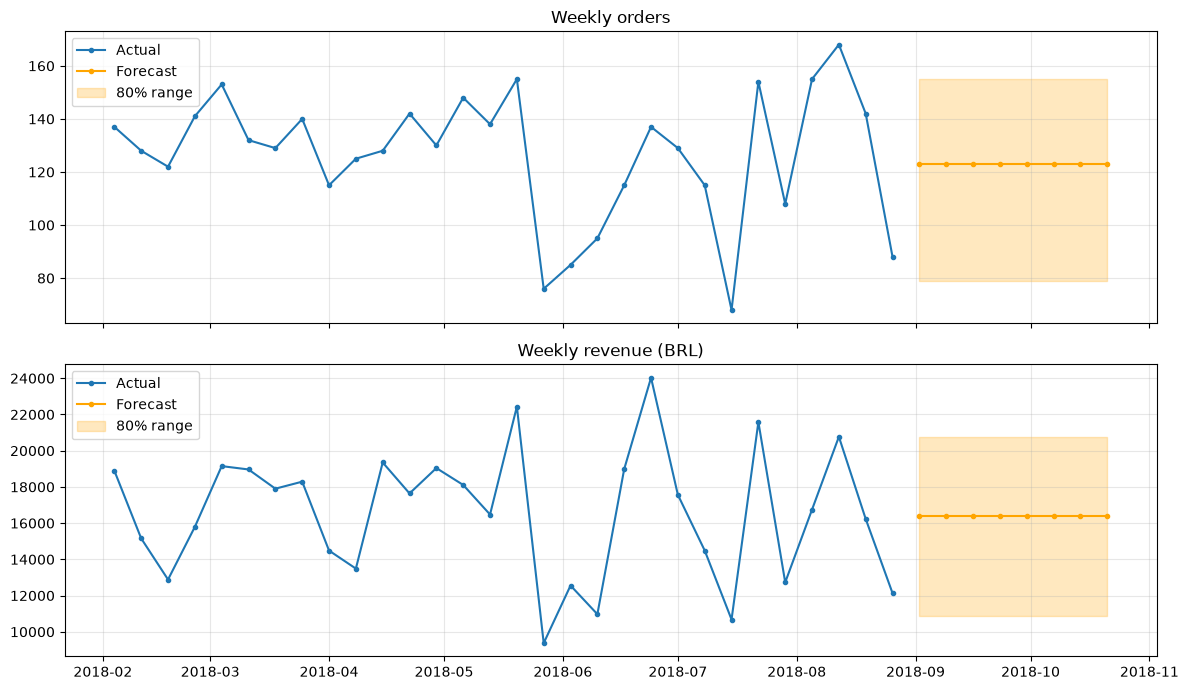

In [22]:
forecast_table = pd.DataFrame({"week_ending": future_dates})
for col in ["orders", "revenue"]:
    forecast_table[col + "_forecast"] = round(final[col]["level"], 1)
    forecast_table[col + "_lower"] = round(final[col]["lower"], 1)
    forecast_table[col + "_upper"] = round(final[col]["upper"], 1)

forecast_table.to_csv("forecast_orders_revenue.csv", index=False)
print(forecast_table.head(3))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
recent = weekly.iloc[-30:]
titles = {"orders": "Weekly orders", "revenue": "Weekly revenue (BRL)"}

for ax, col in zip(axes, ["orders", "revenue"]):
    ax.plot(recent.index, recent[col], marker="o", markersize=3, label="Actual")
    ax.plot(future_dates, [final[col]["level"]] * HORIZON_FINAL,
            color="orange", marker="o", markersize=3, label="Forecast")
    ax.fill_between(future_dates, final[col]["lower"], final[col]["upper"],
                    color="orange", alpha=0.25, label="80% range")
    ax.set_title(titles[col])
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("final_forecast.png", dpi=150)
plt.show()

The forecast for the next 8 weeks (September to October 2018) is about 123 orders and 16,400 BRL per week. The 80% range is wide, from about 79 to 155 orders, because the weekly numbers change a lot. The forecast is flat because the data does not show a clear trend after 2017 and we only have around 20 months, which is not enough to learn a yearly pattern. In the backtest, forecasts 8 weeks ahead had an error of about 19% for orders and 22% for revenue.

## 11. Orders in the three biggest states

Now we forecast the weekly orders for São Paulo (SP), Rio de Janeiro (RJ) and Minas Gerais (MG). These three states have about two thirds of the valid orders. We use the state of the customer.

RJ and MG only have around 11 orders per week, and each of them has one week with zero orders. MAPE divides by the real value, so it breaks when the value is zero or very small. For this reason we use WAPE here, which is the total error divided by the total number of real orders.

We use the same method as before: the average of the last weeks, tested with the same 8-week backtest.

In [23]:
customers = pd.read_excel(FILE, sheet_name="Customers")
valid_state = valid.merge(customers[["customer_id", "customer_state"]], on="customer_id")

states = ["SP", "RJ", "MG"]
top3 = valid_state["customer_state"].value_counts().head(3)
print(top3)
print("Share of valid orders:", round(top3.sum() / len(valid_state) * 100, 1), "%")

state_weekly = pd.DataFrame(index=weekly.index)
for s in states:
    counts = (valid_state[valid_state["customer_state"] == s]
              .set_index("order_purchase_timestamp")
              .resample("W-SUN").size())
    state_weekly[s] = counts.reindex(weekly.index, fill_value=0)

print(state_weekly.describe().round(1))

customer_state
SP    3325
RJ     976
MG     907
Name: count, dtype: int64
Share of valid orders: 65.9 %
         SP    RJ    MG
count  85.0  85.0  85.0
mean   39.0  11.5  10.7
std    20.0   6.1   6.5
min     4.0   0.0   0.0
25%    24.0   8.0   7.0
50%    36.0  11.0  10.0
75%    53.0  14.0  14.0
max    90.0  35.0  41.0


In [24]:
def wape(actual, pred):
    return np.sum(np.abs(actual - pred)) / np.sum(actual) * 100

for s in states:
    rows = []
    for w in [4, 8, 12, 16, 26]:
        actual_all, pred_all = [], []
        for o in origins8:
            actual_all.append(state_weekly[s].iloc[o:o + HORIZON_FINAL].values)
            pred_all.append(np.full(HORIZON_FINAL, state_weekly[s].iloc[:o].iloc[-w:].mean()))

        actual = np.concatenate(actual_all)
        pred = np.concatenate(pred_all)
        rows.append({"window (weeks)": w,
                     "WAPE %": round(wape(actual, pred), 1),
                     "RMSE": round(rmse(actual, pred), 1)})

    print(s)
    print(pd.DataFrame(rows).to_string(index=False))
    print()

SP
 window (weeks)  WAPE %  RMSE
              4    21.2  14.8
              8    18.3  12.6
             12    19.2  12.9
             16    20.8  13.9
             26    25.2  16.3

RJ
 window (weeks)  WAPE %  RMSE
              4    33.9   6.2
              8    29.4   5.4
             12    27.5   5.1
             16    26.9   5.1
             26    27.7   5.4

MG
 window (weeks)  WAPE %  RMSE
              4    37.2   6.7
              8    31.5   5.5
             12    29.2   5.1
             16    28.1   4.9
             26    29.0   5.0



SP | forecast per week: 58.7 | 80% range: 46.0 to 79.8
RJ | forecast per week: 13.2 | 80% range: 6.2 to 17.0
MG | forecast per week: 12.9 | 80% range: 4.9 to 18.2


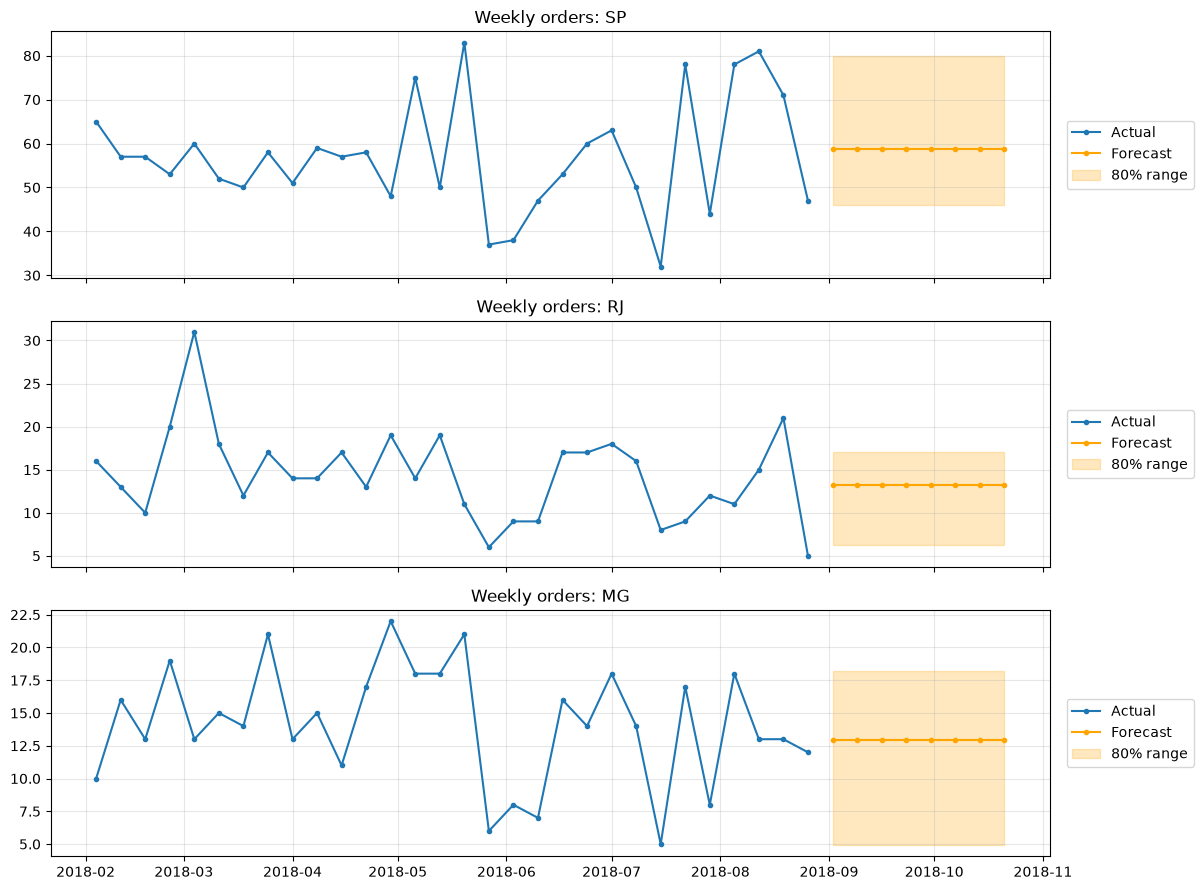

In [45]:
state_final = {}
for s in states:
    errors = []
    for o in origins8:
        level = state_weekly[s].iloc[:o].iloc[-FINAL_WINDOW:].mean()
        errors.extend(state_weekly[s].iloc[o:o + HORIZON_FINAL].values - level)

    low, high = np.percentile(errors, [10, 90])
    level_now = state_weekly[s].iloc[-FINAL_WINDOW:].mean()
    state_final[s] = {"level": level_now,
                      "lower": max(level_now + low, 0),
                      "upper": level_now + high}
    print(s, "| forecast per week:", round(level_now, 1),
          "| 80% range:", round(state_final[s]["lower"], 1), "to", round(state_final[s]["upper"], 1))

state_table = pd.DataFrame({"week_ending": future_dates})
for s in states:
    state_table[s + "_forecast"] = round(state_final[s]["level"], 1)
    state_table[s + "_lower"] = round(state_final[s]["lower"], 1)
    state_table[s + "_upper"] = round(state_final[s]["upper"], 1)
state_table.to_csv("forecast_states.csv", index=False)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
recent = state_weekly.iloc[-30:]
for ax, s in zip(axes, states):
    ax.plot(recent.index, recent[s], marker="o", markersize=3, label="Actual")
    ax.plot(future_dates, [state_final[s]["level"]] * HORIZON_FINAL,
            color="orange", marker="o", markersize=3, label="Forecast")
    ax.fill_between(future_dates, state_final[s]["lower"], state_final[s]["upper"],
                    color="orange", alpha=0.25, label="80% range")
    ax.set_title("Weekly orders: " + s)
    ax.grid(alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))

plt.tight_layout()
plt.savefig("state_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

We forecast the weekly orders of the three biggest states with the average of the last 12 weeks. São Paulo is the easiest one, with an error of about 19%, and the forecast is around 59 orders per week. Rio de Janeiro and Minas Gerais have only about 13 orders per week, so they are harder to forecast (error of about 27 to 29%), and their ranges are wide. São Paulo is also growing: in the last 12 weeks it has about 48% of the orders, compared with 42% in the whole period. We used WAPE instead of MAPE because some weeks have zero orders in RJ and MG.

## 12. Preparing the data for questions 3 and 4

For the machine learning part we need one row per order. We keep only delivered orders that have a delivery date (these are the only ones where we know the real delivery time).

We create two targets:
- delivery_days: the number of days from the purchase to the delivery (question 4).
- is_late: 1 if the order arrived after the estimated delivery date, otherwise 0 (question 3).

We only use information that we know when the customer places the order: the state of the customer and the seller, the main category, the number of items and sellers, the price, the freight, the weight, the promised delivery time (the estimated date minus the purchase date) and the purchase month, weekday and hour.

We do not use the review score, the carrier handoff date or the delivery date, because we only know them later.

In [26]:
sellers = pd.read_excel(FILE, sheet_name="Sellers")
products = pd.read_excel(FILE, sheet_name="Products")
translation = pd.read_excel(FILE, sheet_name="Translation")

for c in ["order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[c] = pd.to_datetime(orders[c])

delivered = orders[(orders["order_status"] == "delivered")
                   & orders["order_delivered_customer_date"].notna()].copy()
print("Delivered orders with a delivery date:", len(delivered))

# targets
delivered["delivery_days"] = (delivered["order_delivered_customer_date"]
                              - delivered["order_purchase_timestamp"]).dt.total_seconds() / 86400
delivered["is_late"] = (delivered["order_delivered_customer_date"]
                        > delivered["order_estimated_delivery_date"]).astype(int)

# promised delivery time, known when the order is placed
delivered["promised_days"] = (delivered["order_estimated_delivery_date"]
                              - delivered["order_purchase_timestamp"]).dt.total_seconds() / 86400

print("Late orders:", delivered["is_late"].sum(), "(", round(delivered["is_late"].mean() * 100, 2), "% )")
print(delivered["delivery_days"].describe().round(1))

Delivered orders with a delivery date: 7745
Late orders: 669 ( 8.64 % )
count    7745.0
mean       12.7
std         9.7
min         1.0
25%         6.8
50%        10.2
75%        15.9
max       187.2
Name: delivery_days, dtype: float64


In [27]:
item_info = (items
    .merge(products[["product_id", "product_category_name", "product_weight_g"]],
           on="product_id", how="left")
    .merge(translation, on="product_category_name", how="left")
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
item_info["category"] = item_info["product_category_name_english"].fillna("unknown")

order_info = item_info.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_sellers=("seller_id", "nunique"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
)

# main category and seller state of the most expensive item in the order
main_item = (item_info.sort_values("price", ascending=False)
             .groupby("order_id")
             .agg(main_category=("category", "first"), seller_state=("seller_state", "first")))

order_info = order_info.join(main_item).reset_index()
print(order_info.shape)

(7929, 8)


In [28]:
df = (delivered
      .merge(order_info, on="order_id", how="left")
      .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left"))

df["freight_share"] = df["total_freight"] / (df["total_price"] + df["total_freight"])
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour

features = ["customer_state", "seller_state", "same_state", "main_category",
            "n_items", "n_sellers", "total_price", "total_freight", "freight_share",
            "total_weight_g", "promised_days",
            "purchase_month", "purchase_weekday", "purchase_hour"]

print("Table shape:", df.shape)
print("Missing values in features:", int(df[features].isna().sum().sum()))
print("Customer states:", df["customer_state"].nunique(),
      "| Seller states:", df["seller_state"].nunique(),
      "| Categories:", df["main_category"].nunique())
print("Same state share:", round(df["same_state"].mean() * 100, 1), "%")
print("Late rate when different / same state:",
      df.groupby("same_state")["is_late"].mean().round(3).to_dict())
print("Orders over 100 days:", (df["delivery_days"] > 100).sum())

Table shape: (7745, 24)
Missing values in features: 0
Customer states: 27 | Seller states: 18 | Categories: 70
Same state share: 36.0 %
Late rate when different / same state: {0: 0.095, 1: 0.072}
Orders over 100 days: 5


We have 7,745 delivered orders. Only 669 of them (8.64%) arrived late, so the late class is small and the accuracy alone would not be a good measure. Orders where the seller and the customer are in the same state are late less often (7.2% against 9.5%). The table has no missing values. There are 5 orders with a delivery time of more than 100 days, which we will check before training the regression model.

## 13. Question 3: first model for late deliveries

We split the orders by time: the first 80% of the orders (older) are for training, and the last 20% (newer) are for testing. This is closer to the real use, because we would train on the past and predict new orders. A random split would mix old and new orders, which is not fair for a time-based problem.

Only 8.6% of the orders are late, so we cannot judge the model by accuracy. We look at ROC-AUC, PR-AUC, precision and recall of the late class. The first model is a logistic regression. We give more weight to the late orders so the model does not just say "never late".

In [29]:
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)

split_at = int(len(df) * 0.8)
train_ml = df.iloc[:split_at]
test_ml = df.iloc[split_at:]

for name, part in [("Train", train_ml), ("Test", test_ml)]:
    print(name, len(part), "orders |",
          part["order_purchase_timestamp"].min().date(), "->",
          part["order_purchase_timestamp"].max().date(),
          "| late rate:", round(part["is_late"].mean() * 100, 2), "%")

Train 6196 orders | 2017-01-05 -> 2018-05-27 | late rate: 9.39 %
Test 1549 orders | 2018-05-27 -> 2018-08-29 | late rate: 5.62 %


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

categorical = ["customer_state", "seller_state", "main_category"]
numeric = [f for f in features if f not in categorical]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", StandardScaler(), numeric),
])

logit = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
])
logit.fit(train_ml[features], train_ml["is_late"])

y_test = test_ml["is_late"].values
proba = logit.predict_proba(test_ml[features])[:, 1]
pred = (proba >= 0.5).astype(int)

In [31]:
print("Share of late orders in the test set:", round(y_test.mean(), 3))
print("Accuracy of 'never late':", round(1 - y_test.mean(), 3))
print()
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC:", round(average_precision_score(y_test, proba), 3),
      "(a random model gets about", round(y_test.mean(), 3), ")")
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:", round(recall_score(y_test, pred), 3))
print("F1:", round(f1_score(y_test, pred), 3))
print("Orders flagged as late:", int(pred.sum()), "of", len(pred))
print(confusion_matrix(y_test, pred))

Share of late orders in the test set: 0.056
Accuracy of 'never late': 0.944

ROC-AUC: 0.713
PR-AUC: 0.108 (a random model gets about 0.056 )
Precision: 0.099
Recall: 0.828
F1: 0.177
Orders flagged as late: 727 of 1549
[[807 655]
 [ 15  72]]


The logistic regression finds some signal but it is weak. The PR-AUC is 0.108, about twice what a random model would get (0.056), and the ROC-AUC is 0.713. With a threshold of 0.5 it catches 72 of the 87 late orders, but it also flags almost half of all the orders, so the precision is only 10%. The share of late orders changes a lot from month to month (for example about 21% in March 2018 and 1.6% in June 2018), and the model cannot know the reasons behind that. The test set has only 87 late orders, so the results are not very stable.

## 14. Can a stronger model or the seller history help?

We try two ideas to improve the late delivery model:
- A stronger model: gradient boosting.
- The history of the seller: the late rate, the number of orders and the average delivery time of the seller in its previous orders. To avoid leakage we only use the orders that were already delivered before the current order was placed. For sellers with few past orders we mix their history with the general late rate, so one late order does not make a seller look very bad.

To compare the models in a way that is useful in practice, we also look at the top 10%: if we could only check the 10% of orders with the highest predicted risk, how many of them are really late, and how many of all the late orders do we catch?

In [32]:
# main seller of each order (seller of the most expensive item)
main_seller = (items.sort_values("price", ascending=False)
               .groupby("order_id")["seller_id"].first().rename("main_seller"))
df = df.merge(main_seller, on="order_id", how="left")

# the split must be created again because we added new columns
train_ml = df.iloc[:split_at]
test_ml = df.iloc[split_at:]

PRIOR = train_ml["is_late"].mean()            # general late rate (training period only)
GLOBAL_DAYS = train_ml["delivery_days"].mean()
K = 10                                         # how strongly we pull small sellers to the general rate

n_past = np.zeros(len(df))
late_past = np.zeros(len(df))
days_sum = np.zeros(len(df))

for seller, g in df.groupby("main_seller"):
    idx = g.index.values
    purchase = g["order_purchase_timestamp"].values
    delivered_at = g["order_delivered_customer_date"].values
    late = g["is_late"].values
    days = g["delivery_days"].values
    for a, i in enumerate(idx):
        known = delivered_at < purchase[a]     # only orders already delivered at this purchase time
        n_past[i] = known.sum()
        late_past[i] = late[known].sum()
        days_sum[i] = days[known].sum()

df["seller_past_orders"] = n_past
df["seller_late_rate_past"] = (late_past + PRIOR * K) / (n_past + K)
df["seller_avg_days_past"] = (days_sum + GLOBAL_DAYS * K) / (n_past + K)

train_ml = df.iloc[:split_at]
test_ml = df.iloc[split_at:]

print("Sellers:", df["main_seller"].nunique())
print("Orders whose seller has no past orders:", int((n_past == 0).sum()),
      "(", round((n_past == 0).mean() * 100, 1), "% )")
print("Median past orders per order:", df["seller_past_orders"].median())

Sellers: 1456
Orders whose seller has no past orders: 1776 ( 22.9 % )
Median past orders per order: 4.0


In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier

history_features = features + ["seller_past_orders", "seller_late_rate_past", "seller_avg_days_past"]
y_test = test_ml["is_late"].values
print("Share of late orders in the test set:", round(y_test.mean(), 3), "| late orders:", int(y_test.sum()))
print()

def evaluate(feats, model, name):
    cats = [f for f in feats if f in categorical]
    nums = [f for f in feats if f not in categorical]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
        ("num", StandardScaler(), nums),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(train_ml[feats], train_ml["is_late"])
    proba = pipe.predict_proba(test_ml[feats])[:, 1]

    top = int(len(proba) * 0.10)
    top_idx = np.argsort(-proba)[:top]
    hits = y_test[top_idx].sum()
    print(f"{name:36s} ROC-AUC {roc_auc_score(y_test, proba):.3f} | PR-AUC {average_precision_score(y_test, proba):.3f}"
          f" | top 10%: precision {hits / top:.3f}, recall {hits / y_test.sum():.3f}, lift {(hits / top) / y_test.mean():.1f}x")
    return pipe

boost = dict(max_depth=3, learning_rate=0.05, max_iter=200, class_weight="balanced", random_state=42)

evaluate(features, LogisticRegression(class_weight="balanced", max_iter=2000), "Logistic (base features)")
evaluate(history_features, LogisticRegression(class_weight="balanced", max_iter=2000), "Logistic + seller history")
evaluate(features, HistGradientBoostingClassifier(**boost), "Gradient boosting (base)")
evaluate(history_features, HistGradientBoostingClassifier(**boost), "Gradient boosting + seller history");

Share of late orders in the test set: 0.056 | late orders: 87

Logistic (base features)             ROC-AUC 0.713 | PR-AUC 0.108 | top 10%: precision 0.104, recall 0.184, lift 1.8x
Logistic + seller history            ROC-AUC 0.712 | PR-AUC 0.104 | top 10%: precision 0.097, recall 0.172, lift 1.7x
Gradient boosting (base)             ROC-AUC 0.640 | PR-AUC 0.082 | top 10%: precision 0.084, recall 0.149, lift 1.5x
Gradient boosting + seller history   ROC-AUC 0.630 | PR-AUC 0.083 | top 10%: precision 0.104, recall 0.184, lift 1.8x


We tried two ideas to improve the model: gradient boosting and the history of the seller. Neither of them helped. Gradient boosting was worse than the logistic regression (ROC-AUC 0.64 against 0.71), probably because it learns patterns from the training months that do not repeat later. The seller history did not help because our data is a small sample, so most sellers have only a few past orders (the median is 4, and 23% of the orders have a seller with no past orders). With the full Olist data this feature may work better. We keep the simple logistic regression as the final model for question 3. If we check only the 10% of orders with the highest risk, about 10% of them are really late, which is almost twice the normal rate (5.6%).

## 15. What drives late deliveries?

To see which features matter we use two simple checks on the logistic regression:
- The coefficients of the numeric features. A negative value means that a higher value of the feature makes a late delivery less likely.
- The importance by shuffling: we mix the values of one feature in the test set and see how much the ROC-AUC drops. If the model needs the feature, the score drops a lot.

These checks show what the model uses, not what causes the delay.

In [34]:
final_logit = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
])
final_logit.fit(train_ml[features], train_ml["is_late"])

names = final_logit.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(final_logit.named_steps["model"].coef_[0], index=names)
numeric_coef = coefficients[[n for n in names if n.startswith("num__")]].sort_values()
print("Coefficients of the numeric features (per 1 standard deviation):")
print(numeric_coef.round(2).to_string())

y_test = test_ml["is_late"].values
base_auc = roc_auc_score(y_test, final_logit.predict_proba(test_ml[features])[:, 1])
print("\nROC-AUC on the test set:", round(base_auc, 3))

rng = np.random.default_rng(42)
rows = []
for f in features:
    drops = []
    for _ in range(30):
        shuffled = test_ml.copy()
        shuffled[f] = rng.permutation(shuffled[f].values)
        auc = roc_auc_score(y_test, final_logit.predict_proba(shuffled[features])[:, 1])
        drops.append(base_auc - auc)
    rows.append({"feature": f, "ROC-AUC drop": round(np.mean(drops), 3)})

print("\nImportance (how much the ROC-AUC drops when the feature is shuffled):")
print(pd.DataFrame(rows).sort_values("ROC-AUC drop", ascending=False).to_string(index=False))

Coefficients of the numeric features (per 1 standard deviation):
num__promised_days      -0.64
num__same_state         -0.35
num__n_items            -0.17
num__n_sellers          -0.15
num__purchase_month     -0.05
num__purchase_weekday   -0.04
num__freight_share      -0.02
num__purchase_hour      -0.00
num__total_price         0.02
num__total_weight_g      0.09
num__total_freight       0.20

ROC-AUC on the test set: 0.713

Importance (how much the ROC-AUC drops when the feature is shuffled):
         feature  ROC-AUC drop
   promised_days         0.255
    seller_state         0.029
  customer_state         0.011
   main_category         0.006
       n_sellers         0.002
   freight_share         0.001
   purchase_hour         0.000
     total_price        -0.000
purchase_weekday        -0.000
  purchase_month        -0.001
  total_weight_g        -0.002
         n_items        -0.003
   total_freight        -0.009
      same_state        -0.017


In [35]:
bins = [0, 12, 18, 24, 30, np.inf]
labels = ["up to 12", "12-18", "18-24", "24-30", "over 30"]

for name, part in [("Train", train_ml), ("Test", test_ml)]:
    groups = part.groupby(pd.cut(part["promised_days"], bins=bins, labels=labels),
                          observed=False)["is_late"]
    table = groups.agg(orders="size", late="sum", late_rate="mean")
    table["late_rate"] = (table["late_rate"] * 100).round(1)
    print(name)
    print(table.to_string())
    print()

print("Share of orders with a promise of 12 days or less: train",
      round((train_ml["promised_days"] <= 12).mean() * 100, 1), "%, test",
      round((test_ml["promised_days"] <= 12).mean() * 100, 1), "%")

Train
               orders  late  late_rate
promised_days                         
up to 12          261    22        8.4
12-18             875    87        9.9
18-24            2075   230       11.1
24-30            1714   151        8.8
over 30          1271    92        7.2

Test
               orders  late  late_rate
promised_days                         
up to 12          327    55       16.8
12-18             299    13        4.3
18-24             341     9        2.6
24-30             255     8        3.1
over 30           327     2        0.6

Share of orders with a promise of 12 days or less: train 4.2 %, test 21.1 %


The most important feature by far is the promised delivery time. In the test period, orders promised in 12 days or less were late in 16.8% of the cases, against 0.6% to 4.3% for the other orders, and they contain 55 of the 87 late orders. This relation was almost not visible in the training period, where the late rate was between 7% and 11% for all promise lengths. The share of short-promised orders grew from 4.2% to 21.1% in the last months, so the promises became shorter and this is when they started to matter. The model is linear, so it extended a small trend it learned and it was lucky in the test period. The state of the seller and the customer also help a little, and the other features add almost nothing. These are patterns in the data, not proof of the causes of delay.

## 16. Question 4: how many days will a delivery take?

Now the target is the number of days from the purchase to the delivery. We use the same split as before (older orders for training and the newest 20% for testing) and the same features, which we know when the order is placed.

Delivery times are skewed: most orders arrive in about 10 days, but a few take more than 100. We keep them, but we choose methods that do not let a few very long deliveries control the model.

We compare:
- Two simple baselines: the median delivery time, and the promised days multiplied by a ratio.
- A ridge regression that predicts the logarithm of the days.
- A gradient boosting model trained to minimize the absolute error (MAE), which follows the typical delivery time and ignores the extreme ones.

We measure the error in days with MAE (the average error), RMSE, and R2. The mean error tells us if the model predicts too high or too low on average.

In [36]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_train = train_ml["delivery_days"]
y_test_days = test_ml["delivery_days"]

print("Delivery days | train: median", round(y_train.median(), 2), "mean", round(y_train.mean(), 2),
      "| test: median", round(y_test_days.median(), 2), "mean", round(y_test_days.mean(), 2))

results = []

def add_result(name, pred):
    results.append({
        "model": name,
        "MAE": round(mean_absolute_error(y_test_days, pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test_days, pred)), 2),
        "R2": round(r2_score(y_test_days, pred), 3),
        "mean error": round(np.mean(pred - y_test_days), 2),
    })

# baselines
add_result("Baseline: train median", np.full(len(test_ml), y_train.median()))

ratio = (y_train / train_ml["promised_days"]).median()
add_result("Baseline: promised days x " + str(round(ratio, 2)), test_ml["promised_days"] * ratio)

Delivery days | train: median 11.23 mean 13.65 | test: median 7.29 mean 8.68


In [37]:
cats = categorical
nums = [f for f in features if f not in categorical]

ridge_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cats),
    ("num", StandardScaler(), nums),
])
ridge = Pipeline([("prep", ridge_prep), ("model", Ridge(alpha=10))])
ridge.fit(train_ml[features], np.log1p(y_train))
add_result("Ridge (log of days)", np.expm1(ridge.predict(test_ml[features])))

boost_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
    ("num", "passthrough", nums),
])
boosting = Pipeline([
    ("prep", boost_prep),
    ("model", HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300,
                                            loss="absolute_error", random_state=42)),
])
boosting.fit(train_ml[features], y_train)
add_result("Gradient boosting (MAE loss)", boosting.predict(test_ml[features]))

print(pd.DataFrame(results).to_string(index=False))

                         model  MAE  RMSE     R2  mean error
        Baseline: train median 5.12  6.88 -0.159        2.54
Baseline: promised days x 0.48 4.47  6.61 -0.072        1.49
           Ridge (log of days) 4.43  6.40 -0.005        2.45
  Gradient boosting (MAE loss) 3.80  5.88  0.154        1.21


Gradient boosting trained with the absolute error is the best model for the delivery time. Its average error is 3.8 days, compared with 5.1 days when we always predict the median, and it is the only model with a positive R2 (0.15). All the models predict longer times than the real ones (by 1 to 2.5 days on average) because deliveries became faster in the last months: the median delivery time in the test period is 7.3 days, against 11.2 days in the training period. The low R2 shows that most of the delivery time cannot be explained by the information we have when the order is placed.

## 17. Where does the delivery time model make mistakes?

A single average error hides a lot, so we look closer at the predictions of the gradient boosting model on the test set:
- How many predictions are close to the real value.
- The error for short and long deliveries, and for orders sent inside the same state or to another state.
- Which features matter most. We shuffle one feature at a time and see how much the average error grows.

In [38]:
test_ml = test_ml.copy()
test_ml["pred_days"] = boosting.predict(test_ml[features])
test_ml["error"] = test_ml["pred_days"] - test_ml["delivery_days"]
test_ml["abs_error"] = test_ml["error"].abs()

print("MAE:", round(test_ml["abs_error"].mean(), 2), "days")
print("Median absolute error:", round(test_ml["abs_error"].median(), 2), "days")
for d in [3, 5, 7]:
    print("Predictions within", d, "days:", round((test_ml["abs_error"] <= d).mean() * 100, 1), "%")

MAE: 3.8 days
Median absolute error: 2.74 days
Predictions within 3 days: 52.7 %
Predictions within 5 days: 72.9 %
Predictions within 7 days: 87.5 %


In [39]:
bins = [0, 5, 10, 15, 20, np.inf]
labels = ["up to 5", "5-10", "10-15", "15-20", "over 20"]

by_actual = (test_ml.groupby(pd.cut(test_ml["delivery_days"], bins=bins, labels=labels), observed=False)
             .agg(orders=("error", "size"), mean_predicted=("pred_days", "mean"),
                  mean_actual=("delivery_days", "mean"), MAE=("abs_error", "mean"))
             .round(1))
print("By actual delivery time:")
print(by_actual.to_string())

by_state = (test_ml.groupby("same_state")
            .agg(orders=("error", "size"), mean_actual=("delivery_days", "mean"),
                 mean_predicted=("pred_days", "mean"), MAE=("abs_error", "mean"))
            .round(2))
print("\nSame state (1) or different state (0):")
print(by_state.to_string())

By actual delivery time:
               orders  mean_predicted  mean_actual   MAE
delivery_days                                           
up to 5           357             6.1          3.3   2.9
5-10              752             9.8          7.2   3.5
10-15             296            12.4         11.9   2.9
15-20              76            14.0         16.9   4.0
over 20            68            15.1         30.1  15.2

Same state (1) or different state (0):
            orders  mean_actual  mean_predicted   MAE
same_state                                           
0              901        10.74           12.74  4.79
1              648         5.82            5.93  2.43


In [40]:
rng = np.random.default_rng(42)
base_mae = test_ml["abs_error"].mean()
rows = []

for f in features:
    increases = []
    for _ in range(20):
        shuffled = test_ml.copy()
        shuffled[f] = rng.permutation(shuffled[f].values)
        new_mae = mean_absolute_error(shuffled["delivery_days"], boosting.predict(shuffled[features]))
        increases.append(new_mae - base_mae)
    rows.append({"feature": f, "MAE increase (days)": round(np.mean(increases), 3)})

print(pd.DataFrame(rows).sort_values("MAE increase (days)", ascending=False).to_string(index=False))

         feature  MAE increase (days)
   promised_days                0.360
      same_state                0.078
   main_category                0.032
  total_weight_g                0.027
         n_items                0.024
       n_sellers                0.024
   total_freight                0.024
purchase_weekday                0.016
   purchase_hour                0.003
  customer_state                0.002
    seller_state                0.001
  purchase_month                0.000
     total_price               -0.004
   freight_share               -0.007


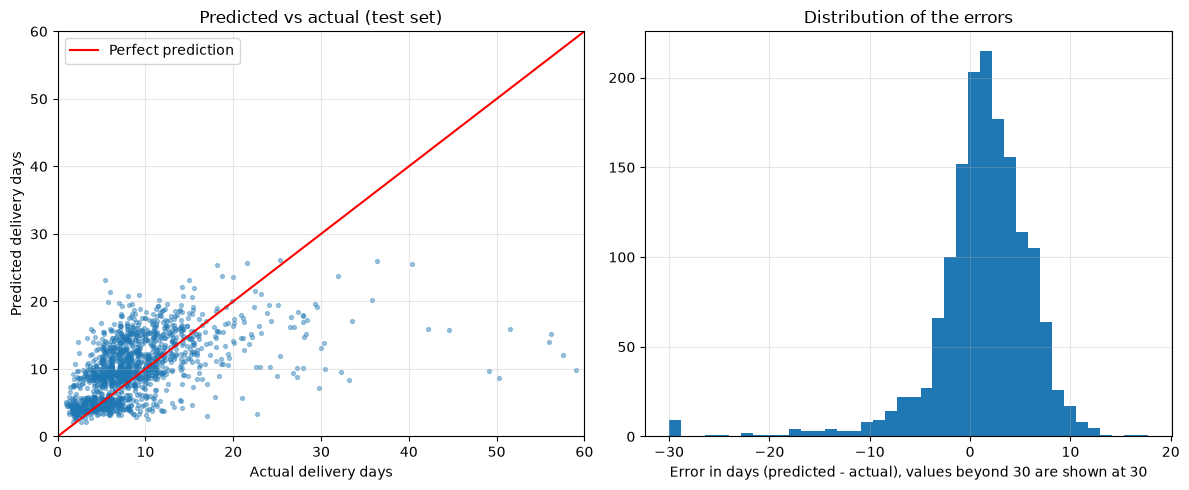

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(test_ml["delivery_days"], test_ml["pred_days"], s=8, alpha=0.4)
axes[0].plot([0, 60], [0, 60], color="red", label="Perfect prediction")
axes[0].set_xlim(0, 60)
axes[0].set_ylim(0, 60)
axes[0].set_xlabel("Actual delivery days")
axes[0].set_ylabel("Predicted delivery days")
axes[0].set_title("Predicted vs actual (test set)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(test_ml["error"].clip(-30, 30), bins=40)
axes[1].set_xlabel("Error in days (predicted - actual), values beyond 30 are shown at 30")
axes[1].set_title("Distribution of the errors")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("delivery_time_model.png", dpi=150)
plt.show()

The typical error of the model is about 2.7 days, and 73% of the predictions are within 5 days of the real delivery time. The model works well for orders sent inside the same state (average error 2.4 days) and worse for orders sent to another state (4.8 days, and it predicts about 2 days too long). It never predicts very long deliveries: the 68 orders that took more than 20 days (30 days on average) are predicted at about 15 days, and these few orders create most of the big errors. The promised delivery time is the most important feature by a large margin, followed by whether the seller and the customer are in the same state, which is a sign of the distance.

## 18. Saving the results for the dashboards

We save the results in CSV files so the dashboard team can use them. The forecasts for questions 1, 2 and 5 were already saved in steps 10 and 11. Now we save the predictions for questions 3 and 4 for every order in the test set, the metrics of the models, and the weekly series with rounded values.

For question 3 we also mark the 10% of the orders with the highest predicted risk of being late.

In [42]:
proba_late = final_logit.predict_proba(test_ml[features])[:, 1]
threshold_top10 = np.percentile(proba_late, 90)

export = pd.DataFrame({
    "order_id": test_ml["order_id"].values,
    "purchase_date": test_ml["order_purchase_timestamp"].dt.date.values,
    "customer_state": test_ml["customer_state"].values,
    "seller_state": test_ml["seller_state"].values,
    "main_category": test_ml["main_category"].values,
    "promised_days": test_ml["promised_days"].round(1).values,
    "actual_delivery_days": test_ml["delivery_days"].round(1).values,
    "predicted_delivery_days": test_ml["pred_days"].round(1).values,
    "actual_late": test_ml["is_late"].values,
    "late_probability": proba_late.round(3),
    "high_risk_top10": (proba_late >= threshold_top10).astype(int),
})
export.to_csv("late_and_delivery_time_predictions.csv", index=False)

flagged = export[export["high_risk_top10"] == 1]
others = export[export["high_risk_top10"] == 0]
print("Rows:", len(export), "| high risk orders:", len(flagged))
print("Late rate among high risk orders:", round(flagged["actual_late"].mean() * 100, 1), "%")
print("Late rate among the other orders:", round(others["actual_late"].mean() * 100, 1), "%")
print("Late orders found in the high risk group:", int(flagged["actual_late"].sum()),
      "of", int(export["actual_late"].sum()))
print()
print(export.head(3).to_string(index=False))

Rows: 1549 | high risk orders: 155
Late rate among high risk orders: 10.3 %
Late rate among the other orders: 5.1 %
Late orders found in the high risk group: 16 of 87

                        order_id purchase_date customer_state seller_state  main_category  promised_days  actual_delivery_days  predicted_delivery_days  actual_late  late_probability  high_risk_top10
bee8e1ed5119e2f2a4bfb408ab6ab177    2018-05-27             SP           RJ bed_bath_table           31.1                  14.8                     13.3            0             0.312                0
3cba3b35a00b76f3a83d1cd84bd9becd    2018-05-27             SC           SC bed_bath_table           51.0                  10.9                     13.7            0             0.041                0
5be9662cf57b643907e692632ff63fdc    2018-05-28             SP           SP sports_leisure           31.6                   9.4                      9.2            0             0.218                0


In [43]:
# Question 3: metrics of the final logistic regression
y_test = test_ml["is_late"].values
pred_05 = (proba_late >= 0.5).astype(int)
top = int(len(proba_late) * 0.10)
top_idx = np.argsort(-proba_late)[:top]
hits = y_test[top_idx].sum()

late_metrics = pd.DataFrame([{
    "model": "Logistic regression",
    "ROC-AUC": round(roc_auc_score(y_test, proba_late), 3),
    "PR-AUC": round(average_precision_score(y_test, proba_late), 3),
    "precision (threshold 0.5)": round(precision_score(y_test, pred_05), 3),
    "recall (threshold 0.5)": round(recall_score(y_test, pred_05), 3),
    "F1 (threshold 0.5)": round(f1_score(y_test, pred_05), 3),
    "precision top 10%": round(hits / top, 3),
    "recall top 10%": round(hits / y_test.sum(), 3),
    "late rate in the test set": round(y_test.mean(), 3),
}])
late_metrics.to_csv("metrics_late_delivery.csv", index=False)

# Question 4: all the models from step 16 (drop_duplicates in case a cell was run twice)
delivery_metrics = pd.DataFrame(results).drop_duplicates(subset="model")
delivery_metrics.to_csv("metrics_delivery_time.csv", index=False)

# weekly series with rounded values
weekly[["orders", "revenue", "black_friday_week"]].round(2).to_csv("weekly_series.csv")

print(late_metrics.T.to_string(header=False))
print()
print(delivery_metrics.to_string(index=False))

model                      Logistic regression
ROC-AUC                                  0.713
PR-AUC                                   0.108
precision (threshold 0.5)                0.099
recall (threshold 0.5)                   0.828
F1 (threshold 0.5)                       0.177
precision top 10%                        0.104
recall top 10%                           0.184
late rate in the test set                0.056

                         model  MAE  RMSE     R2  mean error
        Baseline: train median 5.12  6.88 -0.159        2.54
Baseline: promised days x 0.48 4.47  6.61 -0.072        1.49
           Ridge (log of days) 4.43  6.40 -0.005        2.45
  Gradient boosting (MAE loss) 3.80  5.88  0.154        1.21
